# Visual Analysis of ResNet vs ViT on BloodMNIST

**Phase 1 - Group Non-AI:** Theresa König, Jakob Seibezeder

In our project, we want to compare a pretrained ResNet-18, ResNet-50 and ViT model. The models are trained on BloodMNIST to predict one of 8 classes for each of the 28x28 pixel bloodcell images.


In phase 1 in particular, we want to find answers to the following questions:
1. Which classes are missclassified most often? Why?
2. Are there any differences in missclassifications ResNet vs ViT
3. What influence has data augmentation on our models?

## Data Inspection

### Data Loading

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from matplotlib.lines import Line2D


with np.load("../data/bloodmnist.npz", allow_pickle=False) as dataset:
    t_images = dataset["train_images"]
    t_labels = dataset["train_labels"].reshape(-1)
    test_images = dataset["test_images"]
    test_labels = dataset["test_labels"].reshape(-1)

train_pred = pd.read_csv("../predictions/resnet18_bloodmnist_test.csv", header=None)
train_pred = train_pred.to_numpy()
train_pred_resnet_50 = np.argmax(train_pred[:,1:], axis=1)

models = ["vit", "resnet18", "resnet50"]
augmentations = {"no_aug": "", "rotation": "_rot", "crop": "_crop"}
test_predictions = {}

for m in models:
    test_predictions[m] = {}
    for name, aug in augmentations.items():
        filename = f"../predictions/{m}_bloodmnist_test{aug}.csv"
        test_results = pd.read_csv(filename, header=None).to_numpy()
        test_pred = np.argmax(test_results[:,1:], axis=1)
        test_predictions[m][name] =  test_pred


### Dataset Information

We use the BloodMNIST dataset, a dataset of the MedMNIST+ collection. It contains images of blood cells, classified into 8 classes.

| Label | Name | Cell Type | Subtype | Cell Characteristics |
|---|---|---|---|---|
| 0 | basophils | white | Granulocyte | Large granules in cytoplasm that obscure the cell nucleus |
| 1 | eosinophils | white | Granulocyte | Bilobed nuclei |
| 2 | erythroblasts | red | - | No nucleus; smaller than most other human cells; flexible, biconcave disks |
| 3 | immature granulocytes (metamyelocytes, myelocytes and promyelocytes) | white | Granulocyte | Young granulocytes |
| 4 | lymphocytes | white | Agranulocyte | Large, coarse, dense nucleus |
| 5 | monocytes | white | Agranulocyte | Largest cell type; mononuclear; nucleus is ellipsoidal and might be indented (bean shaped) |
| 6 | neutrophils | white | Granulocyte | Segmented nuclei |
| 7 | platelets (thrombocytes) | Cell fragments | - | Irregularly shaped clear cell fragments |

The training set consists of 11959 samples, while the test set contains 3421. They both have the exact same label distribution.

### Visual Dataset Analysis

* Class representatives
* Per-class mean and variance
* Label distribution

**Dimensionality reduction**

All our scatter plots use T-SNE for dimensionality reduction. We also experimented with PCA and truncated SVD but found that T-SNE separates classes best.

Training set size:  11959
Test set size:  3421


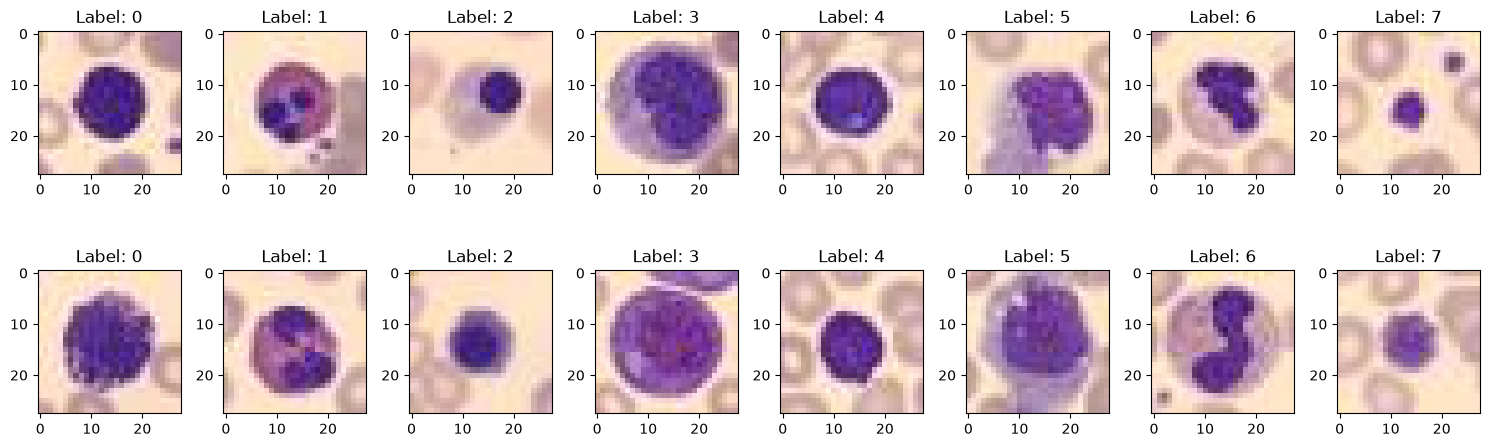

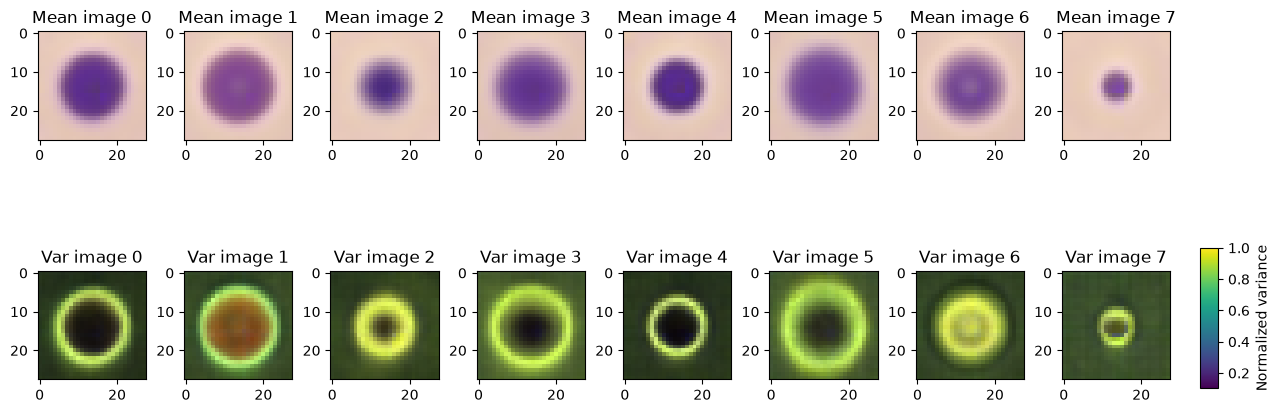

In [33]:
# sample images, mean+var, labels dist

print("Training set size: ", len(t_images))
print("Test set size: ", len(test_images))

fig, axes = plt.subplots(2,8,figsize=(15,5))
for i in range(8): 
    class_img = t_images[t_labels==i]
    axes[0,i].imshow(class_img[0])
    axes[0,i].title.set_text(f"Label: {i}")
    axes[1,i].imshow(class_img[1])
    axes[1,i].title.set_text(f"Label: {i}")

plt.tight_layout()
plt.show()


fig, axes = plt.subplots(2,8,figsize=(15,5))
for i in range(0,8):
    class_img = t_images[t_labels==i]
    mean_image = np.mean(class_img, axis=(0,), dtype=np.int64) 
    var_image = np.var(class_img, axis=(0,), dtype=np.int64) 
    var_image = var_image/np.max(var_image)
    axes[0,i].imshow(mean_image)
    axes[0,i].title.set_text(f"Mean image {i}")    
    im_var = axes[1,i].imshow(var_image)
    axes[1,i].title.set_text(f"Var image {i}")   
fig.subplots_adjust(right=0.88, wspace=0.35, hspace=0.65)
cax = fig.add_axes([0.90, 0.13, 0.012, 0.28])
fig.colorbar(im_var, cax=cax, label="Normalized variance")
plt.show()



true_labels = np.bincount(test_labels)
pred_labels = np.bincount(test_predictions["resnet18"]["no_aug"])
df = pd.DataFrame({"Class": np.arange(8), "Label Count": true_labels, "Predicted labels": pred_labels})
#fig = px.bar(df,x="Class", y=["True labels", "Predicted labels"],barmode="group")
fig = px.bar(df, x="Class", y="Label Count", title="Class Distribution in Test Set")
fig.update_layout(showlegend=False)
fig.show()

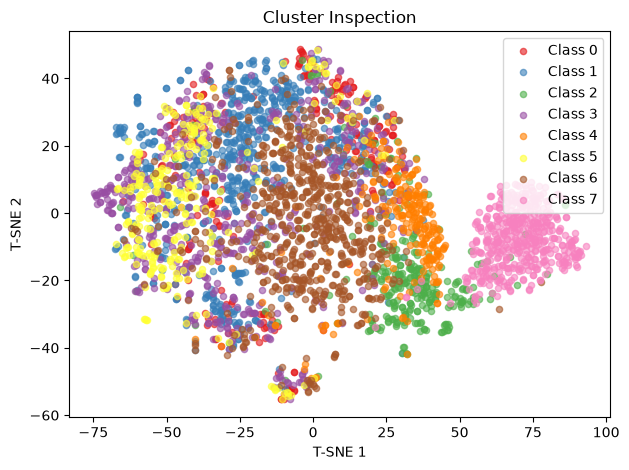

In [ ]:
#pca = PCA(n_components=2)
#test_pca = pca.fit_transform(test_images.reshape((test_images.shape[0], -1)))
tsne = TSNE(n_components=2, perplexity=15)
test_tsne = tsne.fit_transform(test_images.reshape((test_images.shape[0], -1)))
#tsvd = TruncatedSVD(n_components=2)
#train_tsvd = tsvd.fit_transform(test_images.reshape((test_images.shape[0], -1)))

#choose which dim. reduction to use
test_reduction = test_tsne

cmap = plt.get_cmap("Set1")
colors = dict(zip(np.arange(8), [cmap(i) for i in range(8)]))

fig, ax = plt.subplots()
for c in np.arange(8):
    mask = test_labels==c
    ax.scatter(x=test_reduction[mask, 0], y=test_reduction[mask, 1], color=colors[c], label=f"Class {c}",s=20, alpha=0.6)

ax.set_title(f"Cluster Inspection")
ax.set_xlabel("T-SNE 1")
ax.set_ylabel("T-SNE 2")
ax.legend()

plt.tight_layout()
plt.show()



#### Insights

* **Class representatives support characteristics:** The class representatives show the characteristics described in the table above. We can clearly see the segmented nuclei in class 6, representatives of class 5 being the largest ones and red blood cells (class 2) being smaller than the other blood cells and no nucleus visible.
* **Size matters:** The mean plots show us that there is a noticeable difference in size between the different classes, class 2 and 7 being the smallest circles while classes 3 and 5 are the largest. In the variance plots, we see that classes 1 and 6 exhibit the most variance within the cell.
* **Class imbalance:** Class 6 has almost three times as many samples as class 0.
* **Clustering:** Classes seem to separate well into clusters although there seems to be quite some overlap. Class 7 (platelets) is very well separable from other classes. Classes 3 and 5 (both large white blood cells) are overlapping a lot.

## Model Inspection

### Model Introduction

In our project, we want to investigate the behavior of 3 different models.

**ResNet-18**

ResNet-18 (~11.2M parameters) is an 18-layer residual network built using 8 standard 2-layer BasicBlock modules ($[2, 2, 2, 2]$). We used a pretrained instance from the official MedMNIST paper. They reported an AUC of 0.998 and an accuracy of 0.958 on the test set. 

**ResNet-50**

ResNet-50 (~23.5M parameters) is a deeper 50-layer network built using 16 3-layer Bottleneck modules ($[3, 4, 6, 3]$) that project channels down and expand them by a factor of 4. We also use a pretrained instance from the official publication, reporting an AUC of 0.997 and accuracy 0.956 on the test set.

**ViT**

The Vision Transformer we use is a fine-tuned version of google/vit-base-patch16-224 on the medmnist-v2 dataset with ~85.8M parameters. The publisher reports an accuracy of 0.9699 on the test set.

### Sensitivity to Data Augmentation

**Our Hypotheses**
1. **Approximate invariance to rotation:** Since the blood cells in the images do not have a natural orientation, the models are desired to be invariant to rotation. We expect the models to be invariant to rotation by mulitples of 90°, as we do not need padding for these rotations. Neither have the models an explicit rotation invariant architecture nor were they trained on rotated samples, but we suspect that the models are approximately invariant to rotation through the nature of the training set.
2. **Susceptible to Cropping:** As we see in the class-mean visualisations, the size of the blood cells is one of the major characteristics that determines the cell type. Since we lose size information when cropping, we expect more mix-up between classes that have similar cell structure but are differentiated by size.

**Augmentations used**
* Random rotations by 90°, 180° or 270° (no cropping or padding needed)
* Random Cropping with crop area scales between 80-100% of the original image and aspect ratio constraint between 0.9 and 1.1.

All models were trained on data without augmentations. We compare the behavior of these models on three variations of the test set: 
1. no augmetations
2. random rotations
3. random cropping

First, we check the change in accuracy with respect to data augmentation.

In [4]:
accuracy_table = pd.DataFrame(index=models, columns=augmentations)

for m in models:
    for aug in augmentations:
        y_pred = test_predictions[m][aug]
        accuracy_table.loc[m, aug] = np.mean(y_pred == test_labels)

accuracy_table = accuracy_table.astype(float)

df_plot = accuracy_table.reset_index().melt(
    id_vars="index",
    var_name="Augmentation",
    value_name="Accuracy"
).rename(columns={"index": "Model"})

fig = px.bar(df_plot,x="Model", y="Accuracy", color="Augmentation", barmode="group", text_auto=".2%", title="Model Accuracy by Data Augmentation")
fig.update_traces(textposition="outside")
fig.update_layout(yaxis_range=[0, 1.05], legend_title="Augmentation")

fig.show()

#### Insights

### Confusion Matrix

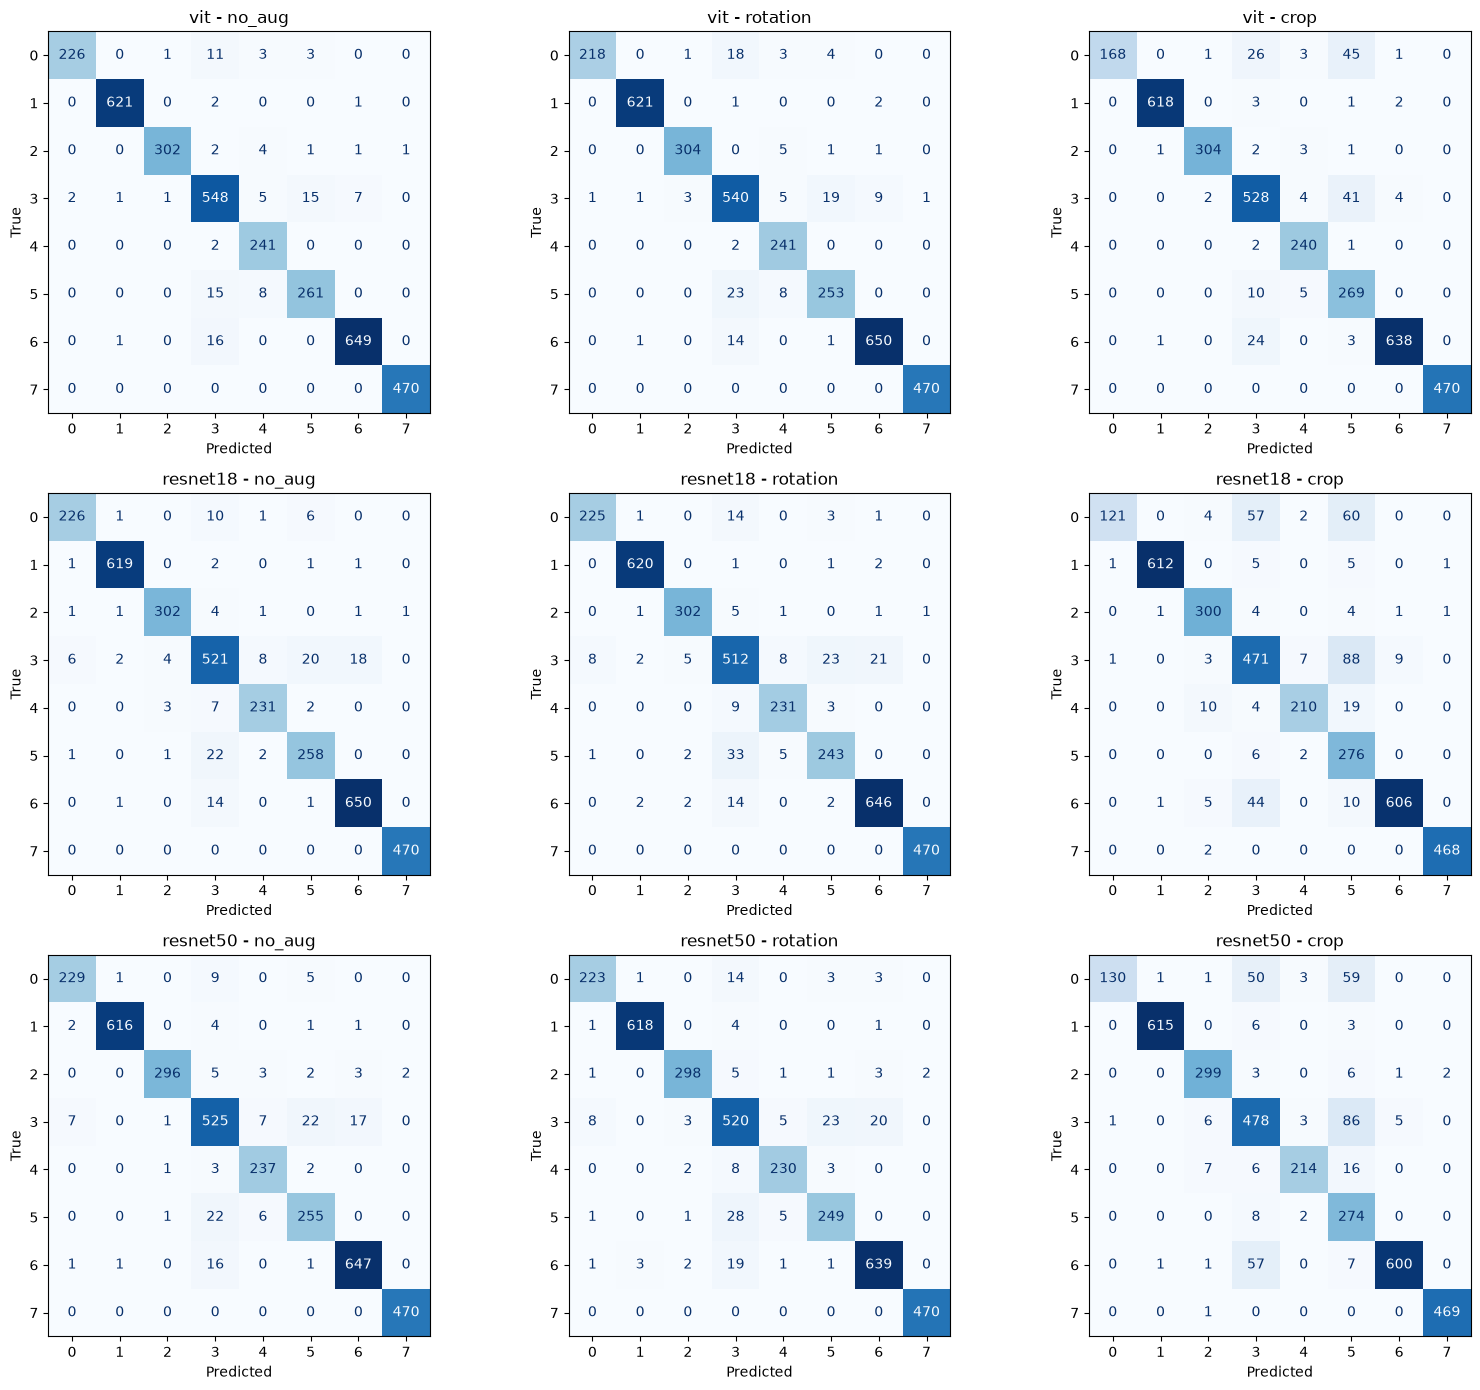

In [5]:
models = ["vit", "resnet18", "resnet50"]
augmentations = ["no_aug", "rotation", "crop"]

fig, axes = plt.subplots(len(models), 3, figsize=(16, 14))

for i, model in enumerate(models):
    for j, aug in enumerate(augmentations):
        y_pred = test_predictions[model][aug]
        cm = confusion_matrix(test_labels, y_pred)

        disp = ConfusionMatrixDisplay(confusion_matrix=cm)

        disp.plot(ax=axes[i, j],cmap="Blues",colorbar=False)

        axes[i, j].set_title(f"{model} - {aug}")
        axes[i, j].set_xlabel("Predicted")
        axes[i, j].set_ylabel("True")

plt.tight_layout()
plt.show()

### Inspect Misclassifications

First, we created a scatter plot of the dimensionality reduced data, color coding the class. To inspect misclassifications, we highlight misclassified samples with larger sized dots and lower transparency. The misclassified dots display the true class as color in the center and predicted class as outline color. This allows us to obtain much information on the nature of misclassifications in a single plot. We can directly extract which classes are over-represented in the misclassifications and which classes are mixed-up most often.

For comparing models and data augmentation influcence, we plot one plot for each model-augmention combination.

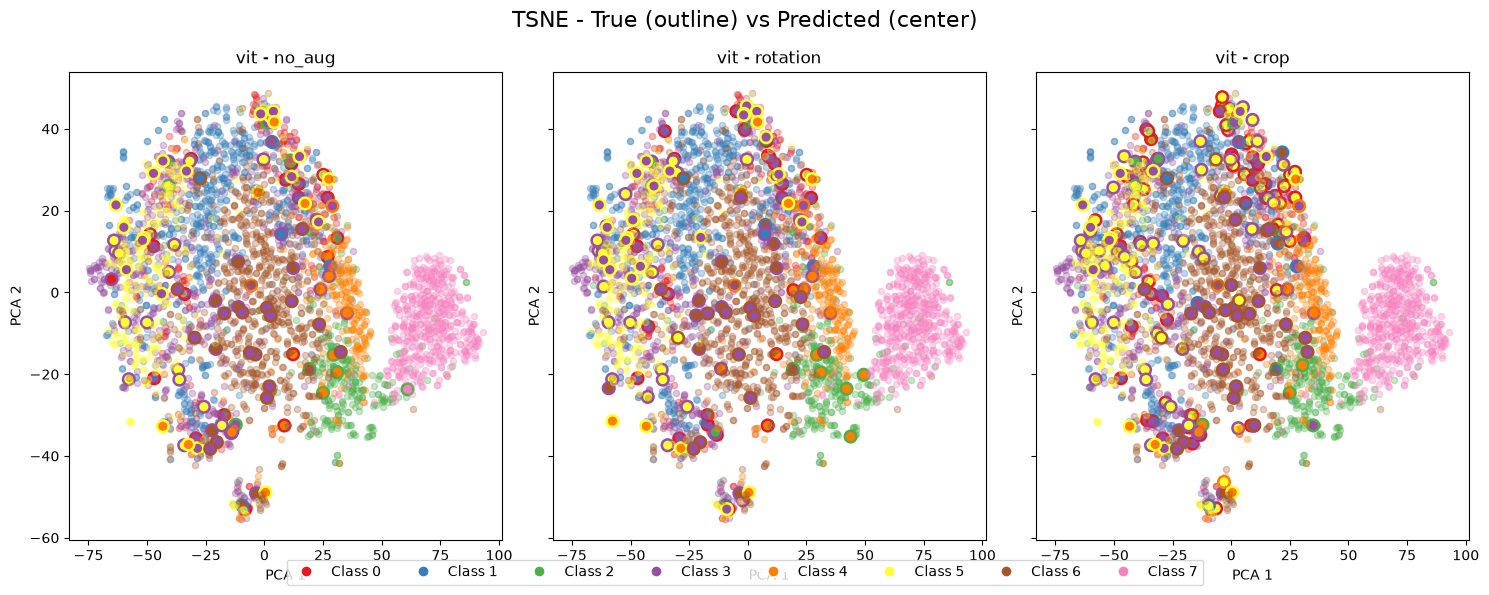

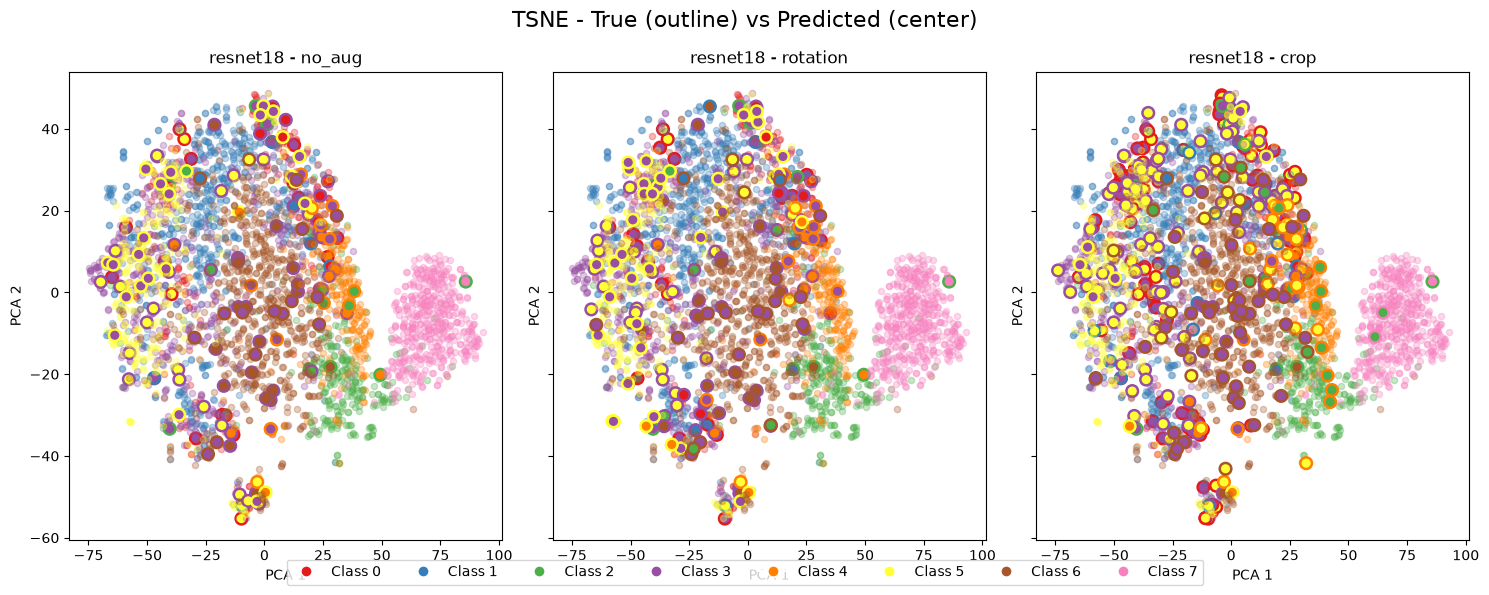

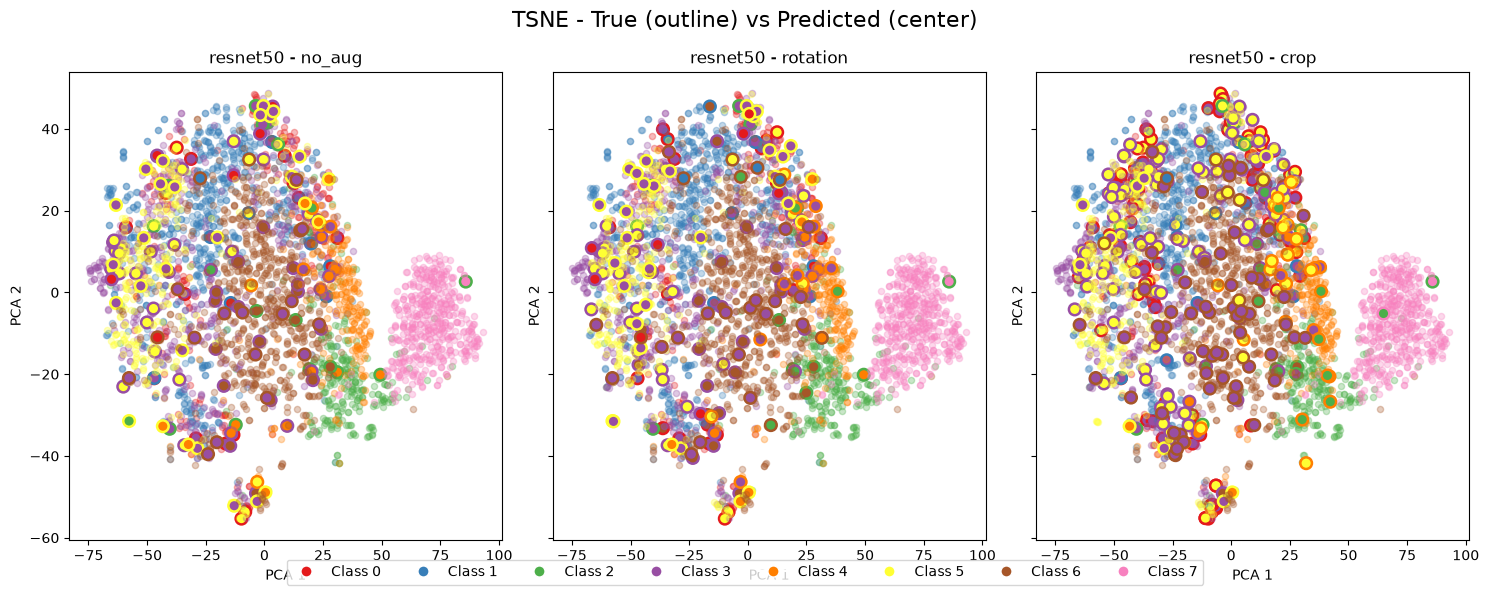

In [6]:
cmap = plt.get_cmap("Set1")
colors = dict(zip(np.arange(8), [cmap(i) for i in range(8)]))

for i, model in enumerate(models):
    fig, axes = plt.subplots(1, len(augmentations), figsize=(15, 6), sharex=True, sharey=True)
    for j, aug in enumerate(augmentations):
        ax = axes[j]

        preds = test_predictions[model][aug]
        misclassified = test_labels != preds

        for c in np.arange(8):
            ax.scatter(x=test_reduction[test_labels==c][:, 0], y=test_reduction[test_labels==c][:, 1], color=colors[c], s=20, alpha=0.3)
            pred_classes = preds[(test_labels==c) & misclassified]
            face_colors = [colors[p] for p in pred_classes]
            ax.scatter(test_reduction[(test_labels==c) & misclassified][:, 0],test_reduction[(test_labels==c) & misclassified][:, 1],
                       s=70,facecolors=face_colors,edgecolors=colors[c], linewidths=1.8)

        ax.set_title(f"{model} - {aug}")
        ax.set_xlabel("PCA 1")
        ax.set_ylabel("PCA 2")

    handles = [Line2D([0], [0], marker='o', color='w',
                      markerfacecolor=colors[c], markersize=8,
                      label=f"Class {c}") for c in range(8)]
    fig.legend(handles=handles, loc='lower center', ncol=8, bbox_to_anchor=(0.5, 0.01))

    fig.suptitle("TSNE - True (outline) vs Predicted (center)", fontsize=16)
    plt.tight_layout()
    plt.show()


#### Insights

TODO: finish interpretation

- in Vit predcitons for class 7 are not influenced by augmentation techniques (likly due to pretraining on image augmented datasets)
- Croping leads to more samples are predicted as class 3(purple) or class 5(yellow) (seen in confusion matrix), since these classes are the largest blood cells (both white blood cells), the croping augmentation enlarges all the images and thus the trained likely believe they are white blood cells, 
- Most of the misclassifications with the rotation augmentation are between the classe 3 and 5, also likely since they are both white blood cells and are very big
- Also, class 0(red) are big white blood cells and especially misclassified with cropping.
- Class 3 and 5 are very similiar in mean and var representation, as can be seen in the plot
- Class 7(pink), which are  platelets (thrombocytes), are the smallest blood cells, as can be seen in mean plot, because of this they are easily seperable in the PCA/TSNE representation. Biologically, they are irregularly shaped clear cell fragments, responsible for clumping when bleeding and are smaller than red or white bloodcells.
- 

### Clusters of Misclassifications

Can we find clusters of misclassifications?

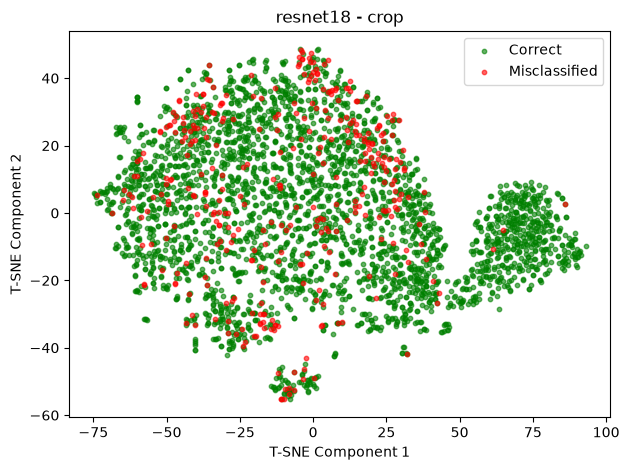

In [7]:
#plotly PCA with wrong predictions with out class coloring

#TODO
model="resnet18" # from ["vit", "resnet18", "resnet50"]
aug="crop" # from ["no_aug", "rotation", "crop"]

fig, ax = plt.subplots()

misclassified = test_labels!=test_predictions[model][aug]
correctly_classified = test_labels==test_predictions[model][aug]
ax.scatter(x=test_reduction[correctly_classified][:, 0], y=test_reduction[correctly_classified][:, 1], c="green", label="Correct", alpha=0.6, s=10)
ax.scatter(x=test_reduction[misclassified][:, 0], y=test_reduction[misclassified][:, 1], c="red", label="Misclassified", alpha=0.6, s=10)
ax.set_title(f"{model} - {aug}")
ax.set_xlabel("T-SNE Component 1")
ax.set_ylabel("T-SNE Component 2")
ax.legend()

plt.tight_layout()
plt.show()

#### Insights

### Model Confidence
Can we identify clusters where the model is particularly undecided?

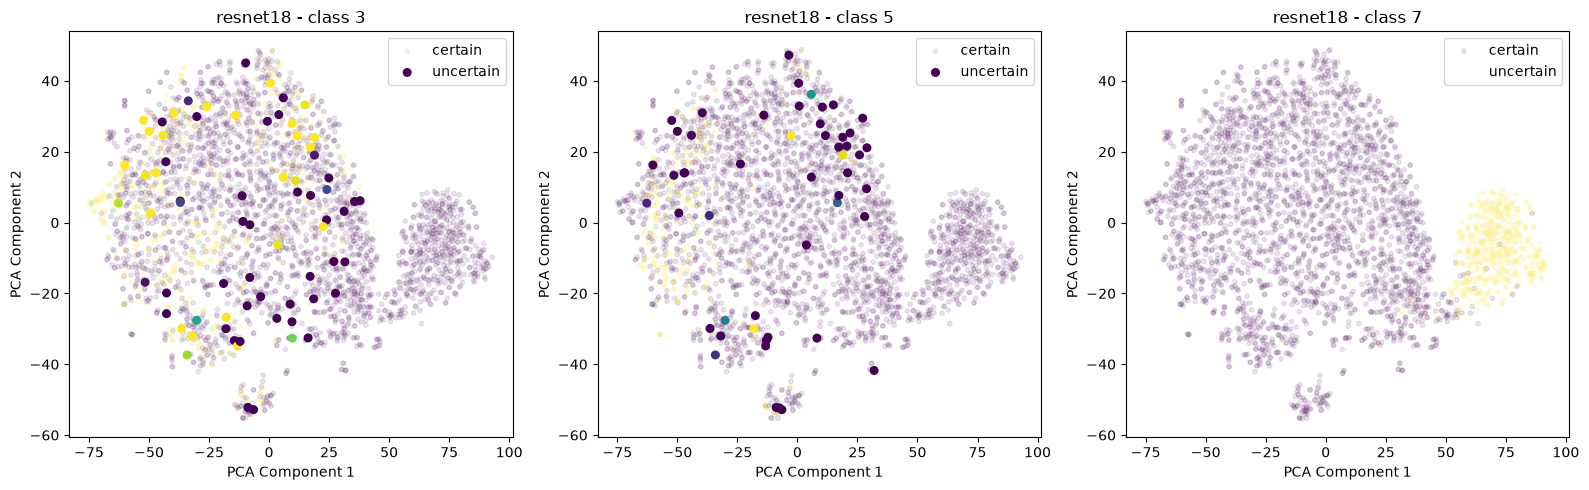

In [9]:
# Select model, augmentation and classes to investigate
model = "resnet18"
aug = "no_aug"
classes = [3,5,7]

# Load confidence scores
conf_scores = pd.read_csv(f"../predictions/{model}_bloodmnist_test{"" if aug=="no_aug" else "_"+aug}.csv", header=None)
conf_scores = conf_scores.to_numpy()


fig, axes = plt.subplots(1, len(classes), figsize=(16, 5))

for j, cl in enumerate(classes):
    uncertain = (test_results[:,cl+1]>0.3) & (test_results[:,cl+1]<0.7) 
    axes[j].scatter(x=test_reduction[~uncertain][:, 0], y=test_reduction[~uncertain][:, 1], c=conf_scores[~uncertain][:, cl+1], label="certain", s=10, alpha=0.1, cmap="viridis")
    axes[j].scatter(x=test_reduction[uncertain][:, 0], y=test_reduction[uncertain][:, 1], c=conf_scores[uncertain][:, cl+1], label="uncertain", s=30, alpha=1.0, cmap="viridis")
    #axes[j].scatter(x=test_reduction[uncertain][:, 0], y=test_reduction[uncertain][:, 1], c="green", label="uncertain", s=30, alpha=1.0, cmap="viridis")
    axes[j].set_title(f"{model} - class {cl}")
    axes[j].set_xlabel("PCA Component 1")
    axes[j].set_ylabel("PCA Component 2")
    axes[j].legend()

plt.tight_layout()
plt.show()

## Summary
todo: einfluss von data aug auf model performance beschreiben